<a href="https://colab.research.google.com/github/83devansh/StatisticsforDataScience/blob/main/practical_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [ ]:
df = pd.read_csv("diabetes.csv")

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Feature Selection**

In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Independent Variables:")
print(X.columns)

print("\nDependent Variable:")
print(y.name)

Independent Variables:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

Dependent Variable:
Outcome


**split data**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


**build desicion tree**

In [ ]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

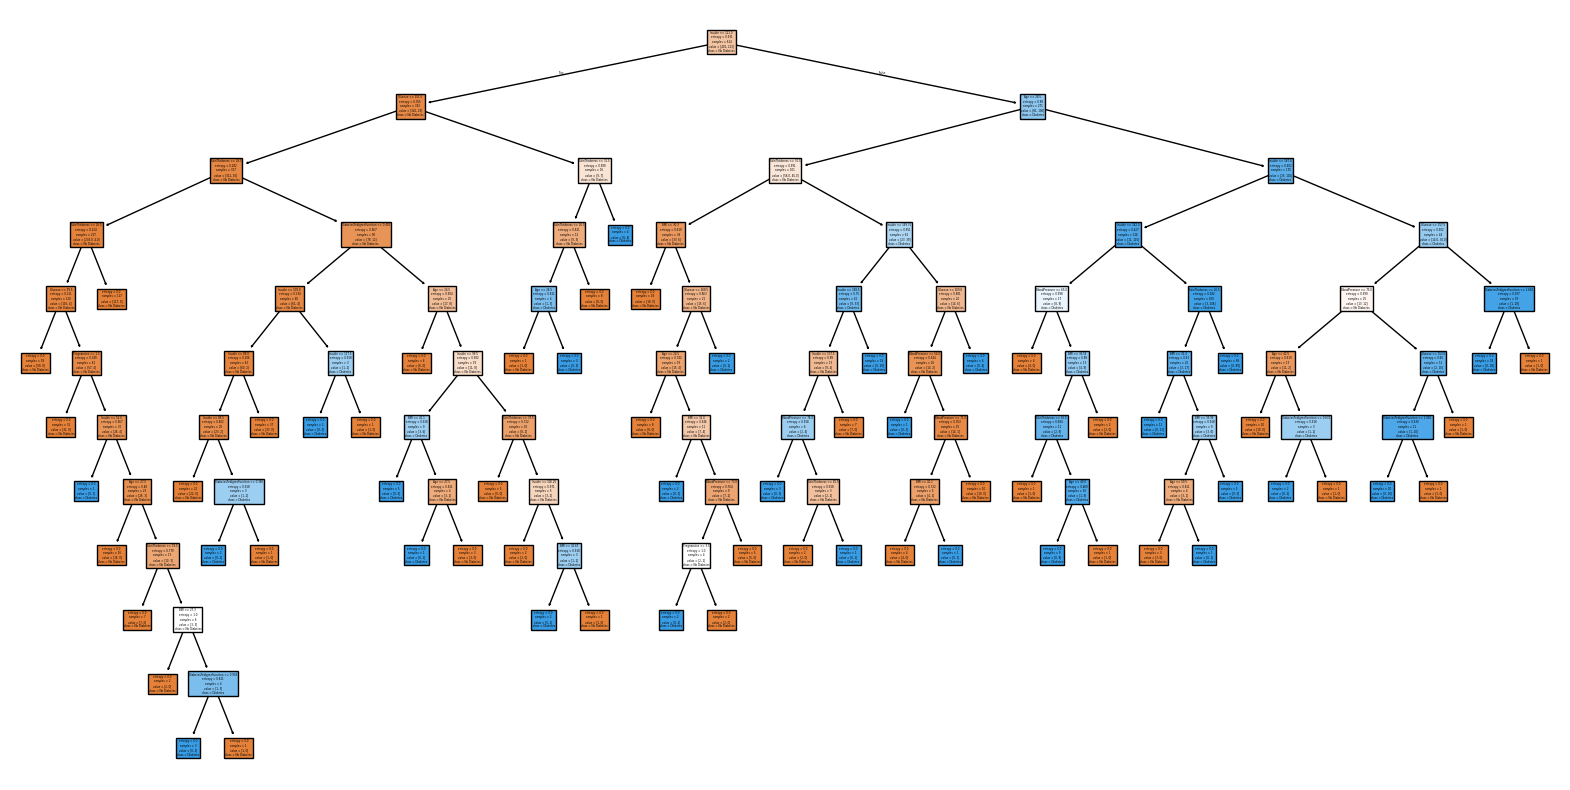

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True
)

plt.show()

**find root node**

In [ ]:
root_index = model.tree_.feature[0]
root_node = X.columns[root_index]

print("Root Node:", root_node)
print("Threshold:", model.tree_.threshold[0])

Root Node: Insulin
Threshold: 121.0


**Glucose was selected as the root node because it produced the highest Information Gain (and a relatively lower impurity), meaning that splitting the dataset based on Glucose resulted in the greatest reduction in uncertainty about the diabetes outcome. Therefore, Glucose provides the most effective first split for the Decision Tree.**

**entropy**

In [ ]:
parent_entropy = model.tree_.impurity[0]

print("Entropy of Root Node:", parent_entropy)

Entropy of Root Node: 0.9312740341054782


**Entropy = 0.9313, indicating a relatively high impurity/uncertainty at the root node before splitting.**

**information gain**

In [ ]:
left = model.tree_.children_left[0]
right = model.tree_.children_right[0]

n_parent = model.tree_.weighted_n_node_samples[0]
n_left = model.tree_.weighted_n_node_samples[left]
n_right = model.tree_.weighted_n_node_samples[right]

information_gain = (
    parent_entropy
    - (n_left / n_parent) * model.tree_.impurity[left]
    - (n_right / n_parent) * model.tree_.impurity[right]
)

print("Information Gain:", information_gain)

Information Gain: 0.34467586825145224


**Information Gain = 0.3447, indicating that the split on Insulin reduces the uncertainty of the target variable by 0.3447.**

**ginni index**

In [ ]:
gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_model.fit(X_train, y_train)

gini_index = gini_model.tree_.impurity[0]

print("Gini Index:", gini_index)

Gini Index: 0.45312417107873826


**Gini Index = 0.4531, indicating the impurity of the root node according to the Gini criterion. A lower Gini value represents a purer node.**

**Insulin was selected as the root node because the Decision Tree identified the split at 121.0 as the best first split using the entropy criterion. The Information Gain of 0.3447 shows a reduction in uncertainty after the split.**